# Datos y demanda histórica

Respondemos a la pregunta 1. Comprobamos las siete fuentes y distinguimos compras de clientes, automatriculaciones, lanzamiento de CSUV, adelantos y señales de falta de stock. Los resultados históricos no identifican toda la demanda potencial.

Ejecuta este notebook desde el principio. Después continúa con [Modelo y validación](02_modelo_y_validacion.ipynb).

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

proyecto = next((p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'src/rutas.py').is_file() and (p / 'data').is_dir()), None)
if proyecto is None:
    raise FileNotFoundError('Abre Jupyter desde la carpeta de entrega o desde notebooks.')
if str(proyecto) not in sys.path:
    sys.path.insert(0, str(proyecto))
from src.rutas import DATOS, RESULTADOS, leer_csv
assert DATOS.parent == proyecto, 'Los datos deben pertenecer a esta copia de entrega.'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                    'axes.spines.right': False, 'font.size': 11, 'axes.titlesize': 13})
print('Datos originales: data/. Resultados: resultados/.')


Datos originales: data/. Resultados: resultados/.


## Comprobaciones de los datos

Solo las celdas vacías se consideran ausentes: `NA` es un código válido de coche.
Revisamos claves, periodos, unidades y relaciones. Las diferencias entre stock y
movimientos se registran sin inventar ventas perdidas ni corregir los CSV originales.
La ficha de CSUV no tiene VM de más de 180 días; la hipótesis económica se explicita
en el cuarto notebook.


In [2]:
from src.calidad import (CLAVES, catalogar, perfilar, auditar,
                         interpretar_ausencias, balance_stock)
import csv
nombres = ['ventas_mensual', 'mercado_mensual', 'stock_mensual', 'macro_mensual',
           'segmentos', 'codigos', 'calendario_A013']
huellas_iniciales = {n + '.csv': hashlib.sha256((DATOS / (n + '.csv')).read_bytes()).hexdigest()
                     for n in nombres}
tablas = {n: leer_csv(n + '.csv') for n in nombres}
catalogo = catalogar(tablas)
catalogo['encoding'] = 'UTF-8 comprobado'
catalogo['separador'] = [csv.Sniffer().sniff((DATOS / (n + '.csv')).read_text()[:12000]).delimiter
                         for n in nombres]
assert catalogo.separador.eq(',').all()
controles = auditar(tablas)
assert controles.estado.eq('OK').all(), 'Hay controles de estructura incumplidos.'
ausentes = interpretar_ausencias(tablas)
balance = balance_stock(tablas['ventas_mensual'], tablas['stock_mensual'])
assert balance.stock_esperado.notna().sum() == 47 * 7
display(catalogo)
display(controles.groupby('estado', as_index=False).agg(controles=('control', 'size')))
display(ausentes.query('pendientes > 0')[['archivo', 'columna', 'interpretacion', 'decision']])
display(balance.loc[balance.diferencia.abs() > 2,
                    ['anio', 'mes', 'segmento', 'stock_anterior', 'wholesale',
                     'retail', 'stock_total', 'stock_esperado', 'diferencia']])


,archivo,filas,columnas,celdas_ausentes,duplicados_completos,encoding,separador
0,ventas_mensual,2520,21,14457,0,UTF-8 comprobado,","
1,mercado_mensual,3024,14,1172,0,UTF-8 comprobado,","
2,stock_mensual,336,12,7,0,UTF-8 comprobado,","
3,macro_mensual,144,19,0,0,UTF-8 comprobado,","
4,segmentos,7,27,1,0,UTF-8 comprobado,","
5,codigos,76,8,14,0,UTF-8 comprobado,","
6,calendario_A013,12,6,0,0,UTF-8 comprobado,","


,estado,controles
0,OK,114


,archivo,columna,interpretacion,decision
10,mercado_mensual,pct_diesel,Composición o potencia media indefinida en una...,Conservar la matrícula y el hueco; estas varia...
11,mercado_mensual,pct_electrificado,Composición o potencia media indefinida en una...,Conservar la matrícula y el hueco; estas varia...
12,mercado_mensual,pct_renting,Renting disponible desde A004; sin media si el...,Conservar la matrícula y el hueco; estas varia...
13,mercado_mensual,cv_medio,Composición o potencia media indefinida en una...,Conservar la matrícula y el hueco; estas varia...
15,segmentos,vm_real_mas_180_eur,CSUV solo tiene cinco meses de historia; VM de...,Necesitará una hipótesis y sensibilidad en la ...


,anio,mes,segmento,stock_anterior,wholesale,retail,stock_total,stock_esperado,diferencia
158,A010,3,MD,331.0,119.0,128,314,322.0,-8.0
159,A010,4,MD,314.0,121.0,125,318,310.0,8.0
202,A009,11,MSUV,887.0,417.0,527,773,777.0,-4.0
203,A009,12,MSUV,773.0,206.0,440,543,539.0,4.0
214,A010,11,MSUV,1204.0,1112.0,891,1421,1425.0,-4.0
220,A011,5,MSUV,1900.0,606.0,789,1712,1717.0,-5.0
226,A011,11,MSUV,1271.0,993.0,755,1506,1509.0,-3.0
293,A009,6,SSUV,781.0,289.0,493,628,577.0,51.0
294,A009,7,SSUV,628.0,254.0,354,478,528.0,-50.0
298,A009,11,SSUV,661.0,428.0,411,675,678.0,-3.0


In [3]:
salida = RESULTADOS / '01_revision_datos'
salida.mkdir(parents=True, exist_ok=True)
perfil = perfilar(tablas)
exportaciones = {'catalogo': catalogo, 'perfil_columnas': perfil,
                 'controles_estructurales': controles, 'valores_ausentes': ausentes,
                 'balance_stock_completo': balance,
                 'incidencias_balance_stock': balance[balance.stock_esperado.notna() & balance.diferencia.ne(0)]}
for nombre, tabla in exportaciones.items():
    tabla.to_csv(salida / (nombre + '.csv'), index=False)
pd.DataFrame([{'archivo': n, 'sha256': h} for n, h in huellas_iniciales.items()]).to_csv(
    salida / 'huellas_fuentes.csv', index=False)
catalogo_json = {'fuentes': [{'nombre': n, 'ruta': 'data/' + n + '.csv',
    'filas': len(d), 'columnas': list(d.columns), 'clave': CLAVES[n],
    'sha256': huellas_iniciales[n + '.csv']} for n, d in tablas.items()]}
(salida / 'catalogo_fuentes.json').write_text(json.dumps(catalogo_json, ensure_ascii=False, indent=2) + '\n')
assert all(hashlib.sha256((DATOS / n).read_bytes()).hexdigest() == h
           for n, h in huellas_iniciales.items())
print('Fuentes comprobadas y conservadas sin cambios.')


Fuentes comprobadas y conservadas sin cambios.


<a id="historia"></a>

## Demanda histórica

**Pregunta:** ¿cuánto compraron los clientes y cuánto creció Kaido en A012?

Restaremos automatriculaciones, compararemos la misma gama y los mismos meses, estudiaremos
los sucesos y señalaremos posibles restricciones de stock. El resultado principal será
**demanda observada atendida**, no una cifra inventada de toda la demanda potencial.

Las ventas no muestran pedidos no atendidos. Tampoco indican qué comprador adelantó
exactamente su compra. Separaremos datos observados, comparaciones y estimaciones.
Ejecuta las secciones en orden, empezando por las comprobaciones de datos anteriores.

Fuente: secciones 4, 5, 8 y 9.1 y anexo 5 del
enunciado (enunciado original del caso).

### 1 Leer y verificar las fuentes auditadas

Ventas aporta las compras; macro, los sucesos; stock, posibles restricciones; mercado
y códigos ayudan a contextualizar. Comprobamos que sean los mismos archivos de la revisión inicial.


In [4]:
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown
from src.historia import (EVENTOS, preparar_demanda, agregar_mensual, resumir_anual,
                         comparar_anios, comparaciones_mismo_perimetro, marcar_stock,
                         referencias_estacionales)

registro = RESULTADOS / '01_revision_datos/huellas_fuentes.csv'
if not registro.exists():
    raise FileNotFoundError('Ejecuta primero el notebook 01.')
huellas = pd.read_csv(registro).set_index('archivo').sha256.to_dict()
for nombre, huella in huellas.items():
    assert hashlib.sha256((DATOS / nombre).read_bytes()).hexdigest() == huella

ventas = leer_csv('ventas_mensual.csv'); macro = leer_csv('macro_mensual.csv')
stock = leer_csv('stock_mensual.csv'); mercado = leer_csv('mercado_mensual.csv')
codigos = leer_csv('codigos.csv')
salida = RESULTADOS / '02_demanda_historica'
salida.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titlesize': 13})


### 2 Calcular compras observadas de clientes

**Clientes observados = matriculaciones − automatriculaciones.**

No restamos ventas especiales: empresas, empleados y colectivos pueden ser clientes
reales. No sumamos los tramos de antigüedad a unidades: ya están incluidos. Tampoco
conocemos la edad de cada automatriculación, así que no podemos descontar todas de
cada tramo para crear una distribución de clientes netos por edad.


,anio,matriculaciones,automatriculaciones,clientes_observados,peso_automatriculacion_pct,crecimiento_clientes_pct
0,A003,6371,1032,5339,16.20,NaN
1,A004,3635,753,2882,20.72,-46.02
2,A005,3611,704,2907,19.50,0.87
3,A006,5472,868,4604,15.86,58.38
4,A007,9561,706,8855,7.38,92.33
5,A008,15007,1540,13467,10.26,52.08
6,A009,18266,1853,16413,10.14,21.88
7,A010,18570,1645,16925,8.86,3.12
8,A011,21362,1819,19543,8.52,15.47
9,A012,23175,2469,20706,10.65,5.95


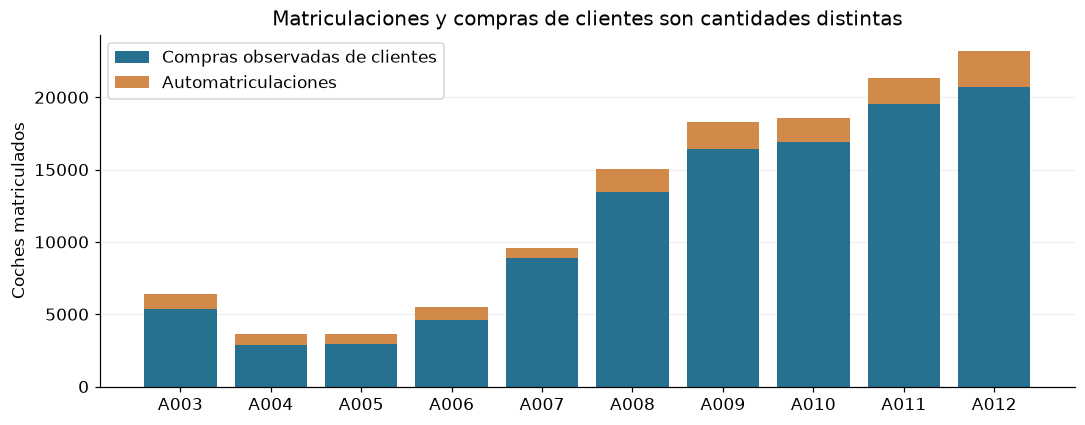

In [5]:
demanda = preparar_demanda(ventas, macro)
mensual = agregar_mensual(demanda)
anual = resumir_anual(demanda)
display(anual.round(2))
assert (demanda.clientes_observados >= 0).all()
assert (demanda.unidades == demanda.clientes_observados + demanda.u_automatriculacion).all()
assert len(demanda) == len(ventas)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(anual.anio, anual.clientes_observados, label='Compras observadas de clientes', color='#26718F')
ax.bar(anual.anio, anual.automatriculaciones, bottom=anual.clientes_observados,
       label='Automatriculaciones', color='#D18A4A')
ax.set(ylabel='Coches matriculados', title='Matriculaciones y compras de clientes son cantidades distintas')
ax.legend(loc='upper left'); ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(salida / '01_matriculaciones_y_clientes.png', dpi=160)
plt.show(); plt.close(fig)


### 3 Comparar A011 con A012 por total, segmento y canal

Comparamos el mismo periodo completo. El crecimiento necesita una base positiva: CSUV
no existía en A011, así que su porcentaje queda vacío, no infinito ni 100 %. Su cambio
absoluto sí se puede calcular. Los totales por segmento y por canal deben sumar lo mismo.


In [6]:
total = comparar_anios(demanda)
por_segmento = comparar_anios(demanda, 'segmento')
por_canal = comparar_anios(demanda, 'canal')
filas_total = []
for nombre, etiqueta in [('matriculaciones', 'Matriculaciones'), ('automatriculaciones', 'Automatriculaciones'), ('clientes', 'Clientes observados')]:
    r = total.iloc[0]
    filas_total.append({'Medida': etiqueta, 'A011': int(r[nombre + '_A011']), 'A012': int(r[nombre + '_A012']),
                        'Cambio en coches': int(r['variacion_' + nombre]), 'Crecimiento %': r['crecimiento_' + nombre + '_pct']})
display(pd.DataFrame(filas_total).round(2))
columnas = ['clientes_A011', 'clientes_A012', 'variacion_clientes', 'crecimiento_clientes_pct',
            'automatriculaciones_A011', 'automatriculaciones_A012']
display(por_segmento[['segmento'] + columnas].round(2))
display(por_canal[['canal'] + columnas].round(2))
assert por_segmento.loc[por_segmento.segmento == 'CSUV', 'crecimiento_clientes_pct'].isna().all()
assert por_segmento.variacion_clientes.sum() == total.variacion_clientes.iloc[0]
assert por_canal.variacion_clientes.sum() == total.variacion_clientes.iloc[0]


,Medida,A011,A012,Cambio en coches,Crecimiento %
0,Matriculaciones,21362,23175,1813,8.49
1,Automatriculaciones,1819,2469,650,35.73
2,Clientes observados,19543,20706,1163,5.95


,segmento,clientes_A011,clientes_A012,variacion_clientes,crecimiento_clientes_pct,automatriculaciones_A011,automatriculaciones_A012
0,B,1517,1623,106,6.99,276,141
1,C,3284,3696,412,12.55,247,493
2,CSUV,0,1192,1192,NaN,0,243
3,MD,1016,591,-425,-41.83,151,164
4,MSUV,8296,7481,-815,-9.82,519,732
5,S,415,488,73,17.59,115,101
6,SSUV,5015,5635,620,12.36,511,595


,canal,clientes_A011,clientes_A012,variacion_clientes,crecimiento_clientes_pct,automatriculaciones_A011,automatriculaciones_A012
0,ALQUILADORES,561,495,-66,-11.76,0,0
1,EMPRESAS_RENTING,3272,3391,119,3.64,1524,1995
2,PARTICULARES,15710,16820,1110,7.07,295,474


### 4 Separar automatriculaciones, gama existente y lanzamiento

El crecimiento de matriculaciones mezcla tres componentes. Esta descomposición es una
identidad contable de unidades, no una prueba de por qué cambió el comportamiento de
los compradores. CSUV empezó en agosto de A012 y añade un segmento sin base en A011.


In [7]:
gama_previa = set(demanda[(demanda.anio == 'A011') & (demanda.unidades > 0)].segmento)
clientes_nuevos = int(demanda[(demanda.anio == 'A012') & (~demanda.segmento.isin(gama_previa))].clientes_observados.sum())
delta_existentes = int(por_segmento[por_segmento.segmento.isin(gama_previa)].variacion_clientes.sum())
delta_auto = int(total.variacion_automatriculaciones.iloc[0])
descomposicion = pd.DataFrame({'componente': ['Cambio de automatriculaciones', 'Clientes de nuevos segmentos',
                                           'Cambio de clientes de gama existente'],
                              'variacion_coches': [delta_auto, clientes_nuevos, delta_existentes]})
display(descomposicion)
assert descomposicion.variacion_coches.sum() == total.variacion_matriculaciones.iloc[0]
print('Cambio total de matriculaciones:', int(total.variacion_matriculaciones.iloc[0]), 'coches')
print('Primera venta registrada de CSUV:', ventas[(ventas.segmento == 'CSUV') & (ventas.unidades > 0)].periodo.min())


,componente,variacion_coches
0,Cambio de automatriculaciones,650
1,Clientes de nuevos segmentos,1192
2,Cambio de clientes de gama existente,-29


Cambio total de matriculaciones: 1813 coches
Primera venta registrada de CSUV: A0120801


### 5 Comparar ventanas de meses y estudiar los sucesos

La gama existente y los siete segmentos responden preguntas distintas. Enero a octubre
evita el adelanto de noviembre-diciembre A012, pero **A011 ya tiene adelanto en agosto
y caída de septiembre a diciembre**. Esa comparación no está completamente libre de sucesos.

Añadimos los mismos meses sin sucesos marcados en ninguno de los dos años: enero a julio.
Comparar siete meses no permite afirmar cuál fue la demanda latente del año completo.


,comparacion,segmentos,meses,clientes_A011,clientes_A012,variacion_coches,crecimiento_pct
0,Año completo,"B, C, MD, MSUV, S, SSUV","1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12",19543,19514,-29,-0.15
1,Enero a octubre,"B, C, MD, MSUV, S, SSUV","1, 2, 3, 4, 5, 6, 7, 8, 9, 10",16178,15470,-708,-4.38
2,Meses sin sucesos marcados en ambos años,"B, C, MD, MSUV, S, SSUV","1, 2, 3, 4, 5, 6, 7",11586,11225,-361,-3.12


,anio,mes,incentivo_publico,adelanto_compras,caida_tras_adelanto,subida_iva
127,A011,8,0,1,0,0
128,A011,9,0,0,1,0
129,A011,10,0,0,1,0
130,A011,11,0,0,1,0
131,A011,12,0,0,1,0
142,A012,11,0,1,0,0
143,A012,12,0,1,0,0


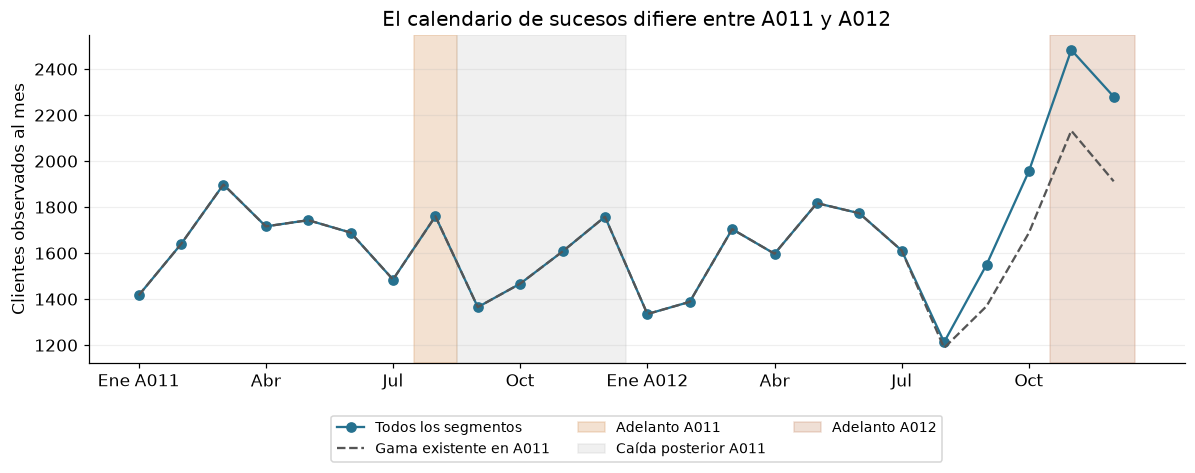

In [8]:
comparables = comparaciones_mismo_perimetro(demanda, macro)
display(comparables.round(2))
sucesos = macro[macro[EVENTOS].max(axis=1) > 0].copy()
display(sucesos[sucesos.anio.isin(['A011', 'A012'])][['anio', 'mes'] + EVENTOS])

curva = demanda[demanda.anio.isin(['A011', 'A012'])].groupby(['t', 'anio', 'mes'], as_index=False).clientes_observados.sum()
existente = demanda[demanda.anio.isin(['A011', 'A012']) & demanda.segmento.isin(gama_previa)].groupby('t').clientes_observados.sum()
curva['gama_existente'] = curva.t.map(existente)
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(curva))
ax.plot(x, curva.clientes_observados, color='#26718F', marker='o', label='Todos los segmentos')
ax.plot(x, curva.gama_existente, color='#555555', linestyle='--', label='Gama existente en A011')
ax.axvspan(6.5, 7.5, color='#D18A4A', alpha=.25, label='Adelanto A011')
ax.axvspan(7.5, 11.5, color='#BBBBBB', alpha=.22, label='Caída posterior A011')
ax.axvspan(21.5, 23.5, color='#BA6E43', alpha=.22, label='Adelanto A012')
ax.set_xticks([0, 3, 6, 9, 12, 15, 18, 21], ['Ene A011', 'Abr', 'Jul', 'Oct', 'Ene A012', 'Abr', 'Jul', 'Oct'])
ax.set(ylabel='Clientes observados al mes', title='El calendario de sucesos difiere entre A011 y A012')
ax.grid(axis='y', alpha=.2)
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.14), ncol=3, fontsize=9)
fig.tight_layout(); fig.savefig(salida / '02_clientes_y_sucesos.png', dpi=160, bbox_inches='tight')
plt.show(); plt.close(fig)


### 6 Contextualizar mercado y producto

El mercado ya incluye a Kaido: no hay que añadirlo. No tenemos automatriculaciones de
todas las marcas rivales. Clientes netos de Kaido entre matriculaciones del mercado es
una **cuota aparente con denominador bruto**, no una cuota pura de clientes finales.

Los ceros de CSUV anteriores a agosto A012 reflejan falta de presencia comercial de
Kaido en esa gama; no ventas fallidas de un producto ya ofrecido. Su mercado sí tiene historia.


In [9]:
contexto = mensual[mensual.anio.isin(['A011', 'A012'])].groupby(['anio', 'segmento'], as_index=False).agg(
    clientes=('clientes_observados', 'sum'), matriculaciones_kaido=('matriculaciones', 'sum'))
mercado_anual = mercado[mercado.anio.isin(['A011', 'A012'])].groupby(['anio', 'segmento'], as_index=False).unidades.sum().rename(columns={'unidades': 'matriculaciones_mercado'})
contexto = contexto.merge(mercado_anual, on=['anio', 'segmento'], validate='one_to_one')
contexto['cuota_aparente_clientes_pct'] = 100 * contexto.clientes / contexto.matriculaciones_mercado
display(contexto.round(2))
display(codigos[codigos.segmento == 'CSUV'][['codigo_modelo', 'generacion', 'primer_mes', 'ultimo_mes', 'unidades', 'en_tarifa_A013']])


,anio,segmento,clientes,matriculaciones_kaido,matriculaciones_mercado,cuota_aparente_clientes_pct
0,A011,B,1517,1793,260684,0.58
1,A011,C,3284,3531,196895,1.67
2,A011,CSUV,0,0,166186,0.00
3,A011,MD,1016,1167,28760,3.53
4,A011,MSUV,8296,8815,147104,5.64
5,A011,S,415,530,867,47.87
6,A011,SSUV,5015,5526,133728,3.75
7,A012,B,1623,1764,230684,0.70
8,A012,C,3696,4189,168093,2.20
9,A012,CSUV,1192,1435,174933,0.68


,codigo_modelo,generacion,primer_mes,ultimo_mes,unidades,en_tarifa_A013
30,DF,1,A0120801,A0121201,1435,1
31,DGK,1,NaN,NaN,0,1
32,DGL,1,NaN,NaN,0,1


### 7 Señalar posibles restricciones de stock

Stock final dividido por clientes del mes es un indicador descriptivo. No es el stock
de seguridad ni prueba una falta durante el mes. Terminar con cero puede significar
que se vendió el último coche sin perder ningún pedido.

El umbral 0,15 es una hipótesis de análisis, no una regla del profesor. Lo contrastamos
con 0,30 y 0,50. Antes de A009 el stock es desconocido, no cero. No repartimos el stock
por canal: primero agregamos las compras de los tres canales.


In [10]:
mensual_stock = marcar_stock(mensual, stock, umbral=.15)
reciente = mensual_stock[mensual_stock.anio.isin(['A011', 'A012'])]
columnas_stock = ['anio', 'mes', 'segmento', 'clientes_observados', 'stock_total',
                  'cobertura_cierre_clientes_mes', 'stock_cero_con_ventas']
display(reciente[reciente.senal_stock_bajo][columnas_stock].round(3))
sensibilidad_stock = []
for umbral in [.15, .30, .50]:
    prueba = marcar_stock(mensual, stock, umbral=umbral)
    for anio in ['A011', 'A012']:
        z = prueba[(prueba.anio == anio) & prueba.senal_stock_bajo]
        sensibilidad_stock.append({'anio': anio, 'umbral': umbral, 'meses_segmento_marcados': len(z),
                                   'segmentos': ', '.join(sorted(z.segmento.unique()))})
sensibilidad_stock = pd.DataFrame(sensibilidad_stock)
display(sensibilidad_stock)
assert mensual_stock.loc[mensual_stock.t < 97, 'stock_total'].isna().all()
assert not mensual_stock.loc[mensual_stock.t < 97, 'senal_stock_bajo'].any()


,anio,mes,segmento,clientes_observados,stock_total,cobertura_cierre_clientes_mes,stock_cero_con_ventas
838,A012,12,S,45,1.0,0.022,False
839,A012,12,SSUV,388,0.0,0.000,True


,anio,umbral,meses_segmento_marcados,segmentos
0,A011,0.15,0,
1,A012,0.15,2,"S, SSUV"
2,A011,0.30,0,
3,A012,0.30,2,"S, SSUV"
4,A011,0.50,0,
5,A012,0.50,2,"S, SSUV"


SSUV acaba diciembre de A012 sin stock después de atender compras; S acaba con un coche.
Son señales para revisar pedidos no atendidos. No permiten contar demanda perdida:
necesitaríamos pedidos, cancelaciones o disponibilidad dentro del mes.


### 8 Comprobar una referencia para el adelanto de compras

Probamos una regla sencilla antes de aplicarla: patrón mensual de A009 o A010, escalado
al nivel de enero-julio A012, para la gama existente. Ambos años de referencia carecen
de sucesos marcados en macro. Noviembre y diciembre no calibran el nivel.

$$k_R = \frac{\sum_{m=1}^{7}C_{A012,m}}{\sum_{m=1}^{7}C_{R,m}},\qquad
\widehat C_{A012,m}^{(R)} = k_R C_{R,m}.$$

La diferencia observada menos referencia **no es el efecto causal del adelanto**:
cambian economía, cuota, producto y stock. Sirve para comprobar si una corrección
sencilla resultaría estable. No imponemos de antemano que la diferencia sea positiva.


,anio_referencia,anio_objetivo,meses_nivel,meses_evento,factor_nivel,clientes_observados_evento,clientes_referencia_evento,diferencia_coches
0,A009,A012,"1, 2, 3, 4, 5, 6, 7","11, 12",1.09,4044,2795.31,1248.69
1,A010,A012,"1, 2, 3, 4, 5, 6, 7","11, 12",1.21,4044,4254.12,-210.12


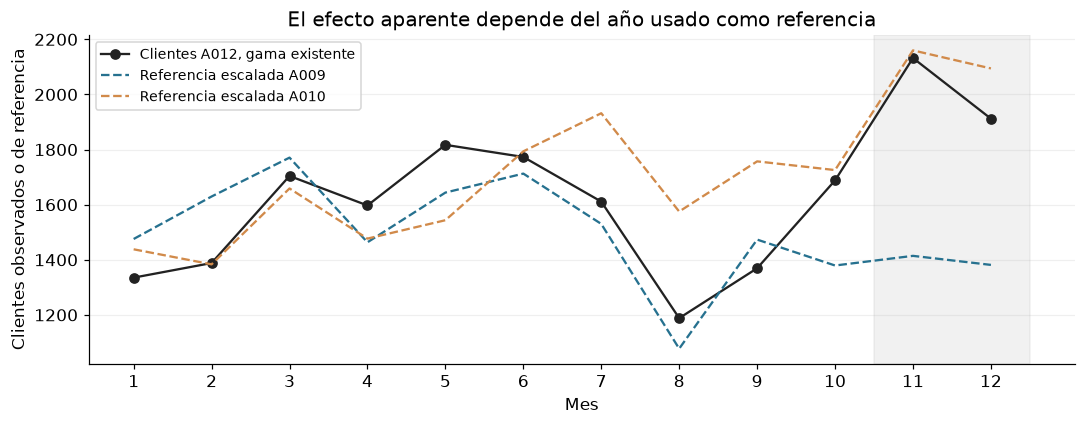

No descontamos esta diferencia: cambia incluso de signo entre referencias.


In [11]:
for referencia in ['A009', 'A010']:
    assert not macro.loc[macro.anio == referencia, EVENTOS].any().any()
referencias, curvas_referencia = referencias_estacionales(demanda)
display(referencias.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
observado = curvas_referencia[curvas_referencia.anio_referencia == 'A009']
ax.plot(observado.mes, observado.clientes_observados, marker='o', color='#222222', label='Clientes A012, gama existente')
for referencia, color in [('A009', '#26718F'), ('A010', '#D18A4A')]:
    r = curvas_referencia[curvas_referencia.anio_referencia == referencia]
    ax.plot(r.mes, r.clientes_referencia, linestyle='--', color=color, label='Referencia escalada ' + referencia)
ax.axvspan(10.5, 12.5, color='#BBBBBB', alpha=.2)
ax.set(xticks=range(1, 13), xlabel='Mes', ylabel='Clientes observados o de referencia',
       title='El efecto aparente depende del año usado como referencia')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=.2)
fig.tight_layout(); fig.savefig(salida / '03_sensibilidad_referencia_adelanto.png', dpi=160)
plt.show(); plt.close(fig)
print('No descontamos esta diferencia: cambia incluso de signo entre referencias.')


**Decisión:** descartar esta regla como limpieza definitiva. Elegir una referencia u otra
produciría una cifra arbitraria. Conservamos compras observadas e indicadores de sucesos.
En el notebook 02 estudiaremos si un modelo con economía y calendario permite una
normalización mejor justificada; incluso entonces tendría supuestos.

No trasladamos automáticamente unidades a A013 ni llamamos demanda real a una cifra
contrafactual sin explicar cómo se obtuvo.


### 9 Guardar la base histórica y sus límites

La base por canal conserva las filas originales y añade clientes, sucesos y presencia
comercial. El stock se guarda en otra tabla agregada por mes y segmento, para evitar
contarlo tres veces. También guardamos la referencia descartada y su explicación.


In [12]:
exportaciones = {'demanda_historica_observada': demanda, 'resumen_anual': anual,
    'comparacion_total_A011_A012': total, 'comparacion_segmentos_A011_A012': por_segmento,
    'comparacion_canales_A011_A012': por_canal, 'descomposicion_crecimiento': descomposicion,
    'comparaciones_mismo_perimetro': comparables, 'sucesos_historicos': sucesos[['t', 'anio', 'mes'] + EVENTOS],
    'mercado_y_cuota_aparente': contexto, 'clientes_y_stock_mensual': mensual_stock,
    'sensibilidad_umbral_stock': sensibilidad_stock, 'referencias_adelanto_no_aplicadas': referencias}
for nombre, tabla in exportaciones.items():
    tabla.to_csv(salida / (nombre + '.csv'), index=False)
metodo = {'base': 'matriculaciones menos automatriculaciones; no se restan ventas especiales',
    'adelanto': 'indicadores conservados; referencia estacional descartada por sensibilidad',
    'stock': 'señales descriptivas; no se imputan ventas perdidas',
    'gama_comparable': sorted(gama_previa), 'stock_umbral_base': .15,
    'pendientes': ['pedidos no atendidos desconocidos', 'efecto causal del adelanto no identificado'],
    'fuentes_sha256': huellas}
(salida / 'metodo_y_limites.json').write_text(json.dumps(metodo, ensure_ascii=False, indent=2) + '\n')
for nombre, huella in huellas.items():
    assert hashlib.sha256((DATOS / nombre).read_bytes()).hexdigest() == huella
print('Resultados guardados en resultados/02_demanda_historica. Fuentes sin cambios.')


Resultados guardados en resultados/02_demanda_historica. Fuentes sin cambios.


### 10 Responder la pregunta del trabajo

La conclusión se genera desde las tablas, para no conservar cifras desactualizadas.
El crecimiento de clientes y el de matriculaciones tienen denominadores distintos.


In [13]:
t = total.iloc[0]
c = comparables.set_index('comparacion')
fmt = lambda x, n=0: f'{x:,.{n}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
anual_existente = c.loc['Año completo', 'crecimiento_pct']
enero_octubre = c.loc['Enero a octubre', 'crecimiento_pct']
enero_julio = c.loc['Meses sin sucesos marcados en ambos años', 'crecimiento_pct']
conclusion = '\n'.join([
    '### Conclusión del análisis histórico', '',
    '- Matriculaciones: {} en A011 y {} en A012, **+{} %**.'.format(fmt(t.matriculaciones_A011), fmt(t.matriculaciones_A012), fmt(t.crecimiento_matriculaciones_pct, 2)),
    '- Compras observadas de clientes: {} y {}, **+{} %**.'.format(fmt(t.clientes_A011), fmt(t.clientes_A012), fmt(t.crecimiento_clientes_pct, 2)),
    '- CSUV añade **{}** clientes. La gama existente cambia **{}** coches, **{} %**.'.format(fmt(clientes_nuevos), fmt(delta_existentes), fmt(anual_existente, 2)),
    '- Con la misma gama, enero-octubre cambia **{} %**; esa ventana todavía incluye sucesos de A011.'.format(fmt(enero_octubre, 2)),
    '- Enero-julio, mismos meses sin sucesos marcados, cambia **{} %**. No mide todo el año.'.format(fmt(enero_julio, 2)), '',
    'El crecimiento publicado mezcla automatriculaciones y ampliación de gama. La gama existente queda casi plana en el año completo y cae en las ventanas comparables anteriores.', '',
    'No conocemos cuántas compras se adelantaron ni cuántas se perdieron por stock. No damos una cifra exacta de demanda potencial.', '',
    'El análisis histórico conserva estos límites. Continúa con el notebook 02, modelo y validación.'
])
display(Markdown(conclusion))
(salida / 'conclusiones.md').write_text(conclusion + '\n', encoding='utf-8')


### Conclusión del análisis histórico

- Matriculaciones: 21.362 en A011 y 23.175 en A012, **+8,49 %**.
- Compras observadas de clientes: 19.543 y 20.706, **+5,95 %**.
- CSUV añade **1.192** clientes. La gama existente cambia **-29** coches, **-0,15 %**.
- Con la misma gama, enero-octubre cambia **-4,38 %**; esa ventana todavía incluye sucesos de A011.
- Enero-julio, mismos meses sin sucesos marcados, cambia **-3,12 %**. No mide todo el año.

El crecimiento publicado mezcla automatriculaciones y ampliación de gama. La gama existente queda casi plana en el año completo y cae en las ventanas comparables anteriores.

No conocemos cuántas compras se adelantaron ni cuántas se perdieron por stock. No damos una cifra exacta de demanda potencial.

El análisis histórico conserva estos límites. Continúa con el notebook 02, modelo y validación.

846